In [ ]:

import os
import pandas as pd

data_path = "/content"

files = [f for f in os.listdir(data_path) if f.endswith(".csv")]

print("Total CSV files found:", len(files))
print("\nAvailable datasets:")

for file in sorted(files):
    print(file)


Total CSV files found: 9

Available datasets:
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [ ]:

orders = pd.read_csv("/content/olist_orders_dataset.csv")

print("Dataset shape:", orders.shape)
print("\nFirst 5 rows:")
display(orders.head())

print("\nColumn names:")
print(orders.columns.tolist())


Dataset shape: (99441, 8)

First 5 rows:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



Column names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


In [ ]:

print("Dataset information:")
orders.info()

print("\nMissing values:")
display(orders.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate order IDs:", orders["order_id"].duplicated().sum())

print("\nOrder status distribution:")
display(orders["order_status"].value_counts().to_frame("Order Count"))


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Missing values:


,Missing Values
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0



Duplicate order IDs: 0

Order status distribution:


,Order Count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [ ]:

import pandas as pd
import numpy as np
import os

# Load the original dataset
orders = pd.read_csv("/content/olist_orders_dataset.csv")

# Preserve the original data; work on a copy
orders_clean = orders.copy()

# Convert date columns to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col], errors="coerce"
    )

# 1. Data-quality audit
audit = pd.DataFrame({
    "Column": orders_clean.columns,
    "Data Type": orders_clean.dtypes.astype(str).values,
    "Missing Values": orders_clean.isnull().sum().values,
    "Missing Percentage": (
        orders_clean.isnull().mean().values * 100
    ).round(2)
})

print("DATA QUALITY AUDIT")
display(audit)

# 2. Check duplicate order IDs
print("Duplicate order IDs:",
      orders_clean["order_id"].duplicated().sum())

# 3. Check invalid date sequences
invalid_approval = (
    orders_clean["order_approved_at"].notna()
    & (orders_clean["order_approved_at"]
       < orders_clean["order_purchase_timestamp"])
)

invalid_carrier = (
    orders_clean["order_delivered_carrier_date"].notna()
    & (orders_clean["order_delivered_carrier_date"]
       < orders_clean["order_purchase_timestamp"])
)

invalid_delivery = (
    orders_clean["order_delivered_customer_date"].notna()
    & (orders_clean["order_delivered_customer_date"]
       < orders_clean["order_purchase_timestamp"])
)

print("\nINVALID DATE SEQUENCES")
print("Approval before purchase:", invalid_approval.sum())
print("Carrier date before purchase:", invalid_carrier.sum())
print("Customer delivery before purchase:", invalid_delivery.sum())

# 4. Calculate delivery duration for valid delivered orders
delivered = orders_clean[
    (orders_clean["order_status"] == "delivered")
    & orders_clean["order_purchase_timestamp"].notna()
    & orders_clean["order_delivered_customer_date"].notna()
].copy()

delivered["delivery_duration_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

print("\nDELIVERY DURATION CHECK")
print("Delivered orders with usable dates:", len(delivered))
print("Negative delivery durations:",
      (delivered["delivery_duration_days"] < 0).sum())

print("\nDelivery duration summary:")
display(delivered["delivery_duration_days"].describe())

# 5. Save interim data without overwriting raw data
os.makedirs("/content/data/interim", exist_ok=True)

orders_clean.to_csv(
    "/content/data/interim/orders_interim.csv",
    index=False
)

print("\nSaved: /content/data/interim/orders_interim.csv")


DATA QUALITY AUDIT


,Column,Data Type,Missing Values,Missing Percentage
0,order_id,object,0,0.00
1,customer_id,object,0,0.00
2,order_status,object,0,0.00
3,order_purchase_timestamp,datetime64[ns],0,0.00
4,order_approved_at,datetime64[ns],160,0.16
5,order_delivered_carrier_date,datetime64[ns],1783,1.79
6,order_delivered_customer_date,datetime64[ns],2965,2.98
7,order_estimated_delivery_date,datetime64[ns],0,0.00


Duplicate order IDs: 0

INVALID DATE SEQUENCES
Approval before purchase: 0
Carrier date before purchase: 166
Customer delivery before purchase: 0

DELIVERY DURATION CHECK
Delivered orders with usable dates: 96470
Negative delivery durations: 0

Delivery duration summary:


,delivery_duration_days
count,96470.000000
mean,12.558217
std,9.546156
min,0.533414
25%,6.766204
50%,10.217477
75%,15.720182
max,209.628611



Saved: /content/data/interim/orders_interim.csv


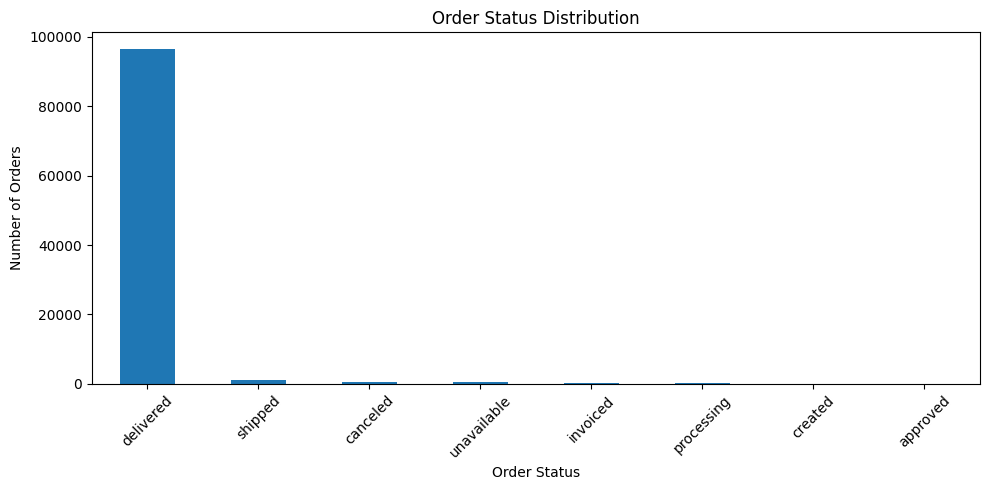

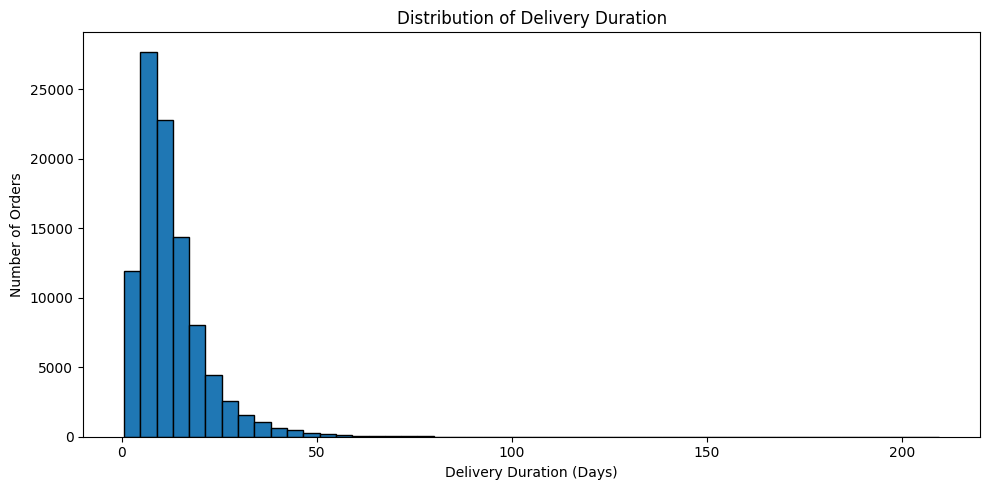

EDA charts saved successfully.


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the interim dataset
orders = pd.read_csv(
    "/content/data/interim/orders_interim.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "order_delivered_carrier_date",
        "order_approved_at"
    ]
)

os.makedirs("/content/reports/figures", exist_ok=True)

# Chart 1: Order status distribution
status_counts = orders["order_status"].value_counts()

plt.figure(figsize=(10, 5))
status_counts.plot(kind="bar")
plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "/content/reports/figures/order_status_distribution.png",
    dpi=300
)
plt.show()

# Chart 2: Delivery duration distribution
delivered = orders[
    (orders["order_status"] == "delivered")
    & orders["order_purchase_timestamp"].notna()
    & orders["order_delivered_customer_date"].notna()
].copy()

delivered["delivery_duration_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

plt.figure(figsize=(10, 5))
plt.hist(
    delivered["delivery_duration_days"],
    bins=50,
    edgecolor="black"
)
plt.title("Distribution of Delivery Duration")
plt.xlabel("Delivery Duration (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.savefig(
    "/content/reports/figures/delivery_duration_distribution.png",
    dpi=300
)
plt.show()

print("EDA charts saved successfully.")


DELIVERY PERFORMANCE KPIs
--------------------------
Eligible delivered orders: 96470
On-time or early orders: 89936
Late orders: 6534
On-time delivery rate: 93.23%
Late delivery rate: 6.77%
Average delay (signed): -11.88 days

Delivery outcome counts:


,Orders
delivery_outcome,
Early,88644
Late,6534
On time,1292


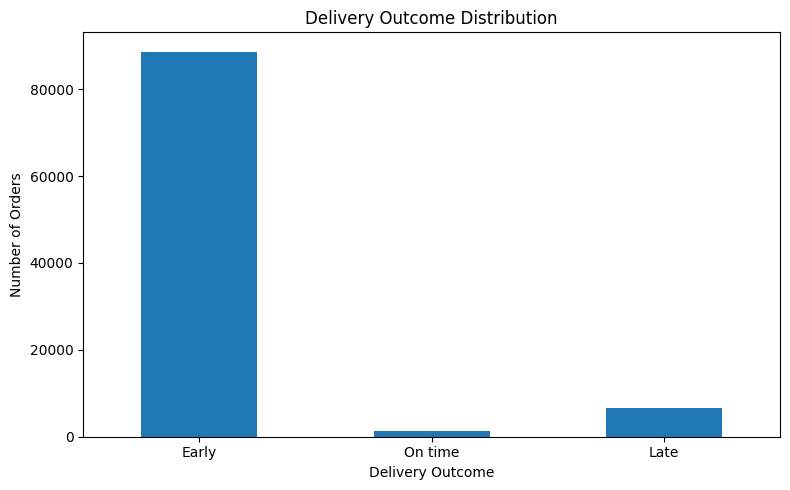

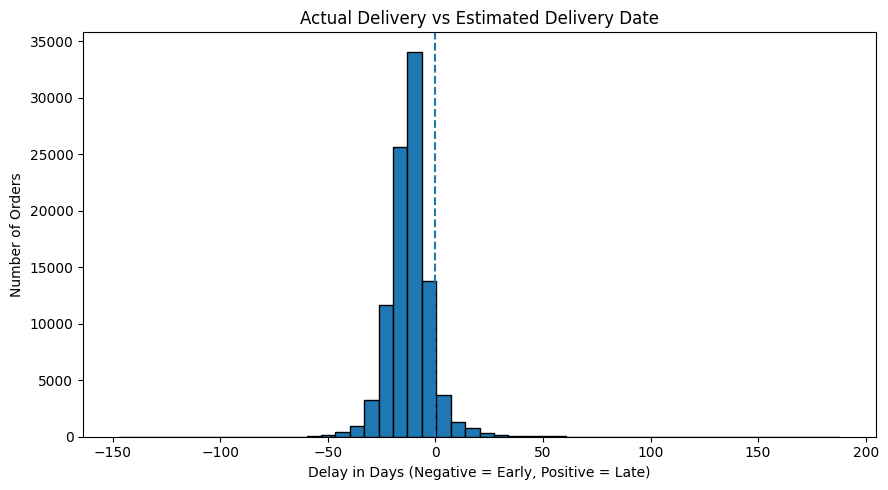

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the interim dataset
orders = pd.read_csv(
    "/content/data/interim/orders_interim.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

# Use delivered orders with both actual and estimated dates
delivery = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

# Positive delay means delivery was late
delivery["delay_days"] = (
    delivery["order_delivered_customer_date"].dt.normalize()
    - delivery["order_estimated_delivery_date"].dt.normalize()
).dt.total_seconds() / 86400

# Classify delivery outcome
delivery["delivery_outcome"] = delivery["delay_days"].apply(
    lambda x: "Late" if x > 0
    else ("On time" if x == 0 else "Early")
)

# Calculate KPIs
total_eligible = len(delivery)
on_time = (delivery["delay_days"] <= 0).sum()
late = (delivery["delay_days"] > 0).sum()

on_time_rate = (
    on_time / total_eligible * 100
    if total_eligible else 0
)

late_rate = (
    late / total_eligible * 100
    if total_eligible else 0
)

average_delay = delivery["delay_days"].mean()

print("DELIVERY PERFORMANCE KPIs")
print("--------------------------")
print("Eligible delivered orders:", total_eligible)
print("On-time or early orders:", on_time)
print("Late orders:", late)
print(f"On-time delivery rate: {on_time_rate:.2f}%")
print(f"Late delivery rate: {late_rate:.2f}%")
print(f"Average delay (signed): {average_delay:.2f} days")

print("\nDelivery outcome counts:")
display(delivery["delivery_outcome"].value_counts().to_frame("Orders"))

# Plot delivery outcomes
os.makedirs("/content/reports/figures", exist_ok=True)

outcome_counts = delivery["delivery_outcome"].value_counts().reindex(
    ["Early", "On time", "Late"], fill_value=0
)

plt.figure(figsize=(8, 5))
outcome_counts.plot(kind="bar")
plt.title("Delivery Outcome Distribution")
plt.xlabel("Delivery Outcome")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "/content/reports/figures/delivery_outcomes.png",
    dpi=300
)
plt.show()

# Plot signed delivery delay
plt.figure(figsize=(9, 5))
plt.hist(delivery["delay_days"], bins=50, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.title("Actual Delivery vs Estimated Delivery Date")
plt.xlabel("Delay in Days (Negative = Early, Positive = Late)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.savefig(
    "/content/reports/figures/delivery_delay_distribution.png",
    dpi=300
)
plt.show()


In [ ]:

import os
import pandas as pd

base = "/content"
os.makedirs(f"{base}/reports", exist_ok=True)
os.makedirs(f"{base}/data/interim", exist_ok=True)

orders = pd.read_csv(f"{base}/data/interim/orders_interim.csv")

# Data dictionary for the orders table
data_dictionary = pd.DataFrame([
    ["order_id", "Unique order identifier", "Identifier"],
    ["customer_id", "Customer identifier associated with the order", "Identifier"],
    ["order_status", "Current recorded order status", "Categorical"],
    ["order_purchase_timestamp", "Date and time the order was placed", "Datetime"],
    ["order_approved_at", "Date and time the order was approved", "Datetime"],
    ["order_delivered_carrier_date", "Date and time the order was handed to the carrier", "Datetime"],
    ["order_delivered_customer_date", "Date and time the customer received the order", "Datetime"],
    ["order_estimated_delivery_date", "Estimated delivery date", "Datetime"]
], columns=["Column", "Description", "Data Type"])

data_dictionary.to_csv(
    f"{base}/reports/data_dictionary.csv", index=False
)

# Save the data-quality audit
audit = pd.DataFrame({
    "column": orders.columns,
    "data_type": orders.dtypes.astype(str).values,
    "missing_values": orders.isnull().sum().values,
    "missing_percentage": (
        orders.isnull().mean().values * 100
    ).round(2)
})

audit.to_csv(
    f"{base}/reports/data_quality_audit.csv", index=False
)

# Save the status distribution
orders["order_status"].value_counts().rename_axis(
    "order_status"
).reset_index(name="order_count").to_csv(
    f"{base}/reports/order_status_summary.csv", index=False
)

print("Week 1 documentation files created:")
print("- reports/data_dictionary.csv")
print("- reports/data_quality_audit.csv")
print("- reports/order_status_summary.csv")


Week 1 documentation files created:
- reports/data_dictionary.csv
- reports/data_quality_audit.csv
- reports/order_status_summary.csv


In [ ]:

import os
import pandas as pd

# Create the reports folder
os.makedirs("/content/reports", exist_ok=True)

# Document the data-cleaning rules
cleaning_rules = pd.DataFrame([
    {
        "Issue": "Missing approval timestamps",
        "Finding": "160 missing values",
        "Cleaning rule": "Keep the records; exclude missing timestamps only from calculations requiring approval time."
    },
    {
        "Issue": "Missing carrier delivery timestamps",
        "Finding": "Missing values present",
        "Cleaning rule": "Keep the records; exclude missing timestamps from carrier-related duration calculations."
    },
    {
        "Issue": "Missing customer delivery timestamps",
        "Finding": "Missing values present",
        "Cleaning rule": "Keep the records; exclude from actual delivery duration and delivery outcome KPIs."
    },
    {
        "Issue": "Duplicate order IDs",
        "Finding": "0 duplicates found",
        "Cleaning rule": "Retain all records; repeat this check after any joins."
    },
    {
        "Issue": "Carrier date before purchase date",
        "Finding": "166 records flagged",
        "Cleaning rule": "Flag for investigation; do not use these timestamps for affected duration calculations until validated."
    },
    {
        "Issue": "Negative customer delivery duration",
        "Finding": "0 found among records with usable dates",
        "Cleaning rule": "Retain valid records and repeat the check after transformations."
    },
    {
        "Issue": "Unusually long delivery duration",
        "Finding": "Maximum approximately 209.63 days",
        "Cleaning rule": "Flag for review; do not remove automatically without evidence."
    },
    {
        "Issue": "Order status",
        "Finding": "Multiple statuses present",
        "Cleaning rule": "Preserve original statuses; define eligible orders separately for each KPI."
    },
    {
        "Issue": "Date fields",
        "Finding": "Parsed using pandas datetime conversion",
        "Cleaning rule": "Use consistent datetime types and document any values converted to missing."
    }
])

# Save the rules
cleaning_rules.to_csv(
    "/content/reports/data_cleaning_rules.csv",
    index=False
)

print("Cleaning rules saved successfully!")
display(cleaning_rules)


Cleaning rules saved successfully!


,Issue,Finding,Cleaning rule
0,Missing approval timestamps,160 missing values,Keep the records; exclude missing timestamps o...
1,Missing carrier delivery timestamps,Missing values present,Keep the records; exclude missing timestamps f...
2,Missing customer delivery timestamps,Missing values present,Keep the records; exclude from actual delivery...
3,Duplicate order IDs,0 duplicates found,Retain all records; repeat this check after an...
4,Carrier date before purchase date,166 records flagged,Flag for investigation; do not use these times...
5,Negative customer delivery duration,0 found among records with usable dates,Retain valid records and repeat the check afte...
6,Unusually long delivery duration,Maximum approximately 209.63 days,Flag for review; do not remove automatically w...
7,Order status,Multiple statuses present,Preserve original statuses; define eligible or...
8,Date fields,Parsed using pandas datetime conversion,Use consistent datetime types and document any...


In [ ]:

import os
import zipfile

zip_path = "/content/week1_project_files.zip"

folders_to_include = [
    "/content/data/interim",
    "/content/reports"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for folder in folders_to_include:
        if os.path.exists(folder):
            for root, dirs, files in os.walk(folder):
                for file in files:
                    file_path = os.path.join(root, file)
                    arcname = os.path.relpath(file_path, "/content")
                    zipf.write(file_path, arcname)

print("Week 1 project files packaged successfully!")
print("ZIP file:", zip_path)


Week 1 project files packaged successfully!
ZIP file: /content/week1_project_files.zip


In [ ]:

from google.colab import files

files.download("/content/week1_project_files.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file == "orders_interim.csv":
            print("Found dataset:", os.path.join(root, file))

In [ ]:
import zipfile

with zipfile.ZipFile("/content/week1_project_files.zip", "r") as zip_ref:
    zip_ref.extractall("/content")

print("ZIP extracted successfully!")

ZIP extracted successfully!


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file == "orders_interim.csv":
            print("Found dataset:", os.path.join(root, file))

Found dataset: /content/data/interim/orders_interim.csv


In [ ]:
import pandas as pd

orders = pd.read_csv("/content/data/interim/orders_interim.csv")

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    if col in orders.columns:
        orders[col] = pd.to_datetime(orders[col], errors="coerce")

print("Dataset loaded successfully!")
print("Rows and columns:", orders.shape)
display(orders.head())

Dataset loaded successfully!
Rows and columns: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [ ]:

import pandas as pd
import numpy as np

# 1. Total orders
total_orders = orders["order_id"].nunique()

# 2. Orders by status
delivered_orders = orders[
    orders["order_status"] == "delivered"
]

total_delivered = delivered_orders["order_id"].nunique()

# 3. Actual delivery duration in days
valid_duration = delivered_orders.dropna(
    subset=[
        "order_purchase_timestamp",
        "order_delivered_customer_date"
    ]
).copy()

valid_duration["delivery_days"] = (
    valid_duration["order_delivered_customer_date"]
    - valid_duration["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Exclude invalid negative durations from the duration KPI
valid_duration = valid_duration[
    valid_duration["delivery_days"] >= 0
]

average_delivery_days = valid_duration["delivery_days"].mean()

# 4. On-time and late delivery
valid_outcomes = delivered_orders.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

actual_date = valid_outcomes[
    "order_delivered_customer_date"
].dt.normalize()

estimated_date = valid_outcomes[
    "order_estimated_delivery_date"
].dt.normalize()

on_time_or_early = (actual_date <= estimated_date).sum()
late_orders = (actual_date > estimated_date).sum()
eligible_orders = len(valid_outcomes)

on_time_rate = (
    on_time_or_early / eligible_orders * 100
    if eligible_orders else np.nan
)

late_rate = (
    late_orders / eligible_orders * 100
    if eligible_orders else np.nan
)

# 5. Create KPI summary
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Orders",
        "Delivered Orders",
        "Orders Eligible for Delivery-Time KPI",
        "Average Delivery Time (Days)",
        "Orders Eligible for Delivery Outcome KPI",
        "On-Time or Early Delivery Rate (%)",
        "Late Delivery Rate (%)"
    ],
    "Value": [
        total_orders,
        total_delivered,
        len(valid_duration),
        round(average_delivery_days, 2),
        eligible_orders,
        round(on_time_rate, 2),
        round(late_rate, 2)
    ]
})

display(kpi_summary)


,KPI,Value
0,Total Orders,99441.00
1,Delivered Orders,96478.00
2,Orders Eligible for Delivery-Time KPI,96470.00
3,Average Delivery Time (Days),12.56
4,Orders Eligible for Delivery Outcome KPI,96470.00
5,On-Time or Early Delivery Rate (%),93.23
6,Late Delivery Rate (%),6.77


In [ ]:

import os

os.makedirs("/content/reports", exist_ok=True)

kpi_summary.to_csv(
    "/content/reports/week2_kpi_summary.csv",
    index=False
)

print("Week 2 KPI summary saved successfully!")


Week 2 KPI summary saved successfully!


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Select delivered orders with valid actual and estimated dates
monthly_orders = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

# Normalize dates to compare calendar delivery dates
monthly_orders["actual_date"] = (
    monthly_orders["order_delivered_customer_date"].dt.normalize()
)

monthly_orders["estimated_date"] = (
    monthly_orders["order_estimated_delivery_date"].dt.normalize()
)

# Identify late deliveries
monthly_orders["is_late"] = (
    monthly_orders["actual_date"] > monthly_orders["estimated_date"]
)

# Group by order purchase month
monthly_orders["purchase_month"] = (
    monthly_orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

monthly_delay = monthly_orders.groupby("purchase_month").agg(
    total_eligible_orders=("order_id", "nunique"),
    late_orders=("is_late", "sum")
).reset_index()

monthly_delay["late_delivery_rate_pct"] = (
    monthly_delay["late_orders"]
    / monthly_delay["total_eligible_orders"] * 100
).round(2)

display(monthly_delay.head(10))


,purchase_month,total_eligible_orders,late_orders,late_delivery_rate_pct
0,2016-09,1,1,100.00
1,2016-10,265,2,0.75
2,2016-12,1,0,0.00
3,2017-01,750,22,2.93
4,2017-02,1653,49,2.96
5,2017-03,2546,116,4.56
6,2017-04,2303,151,6.56
7,2017-05,3545,106,2.99
8,2017-06,3135,95,3.03
9,2017-07,3872,108,2.79


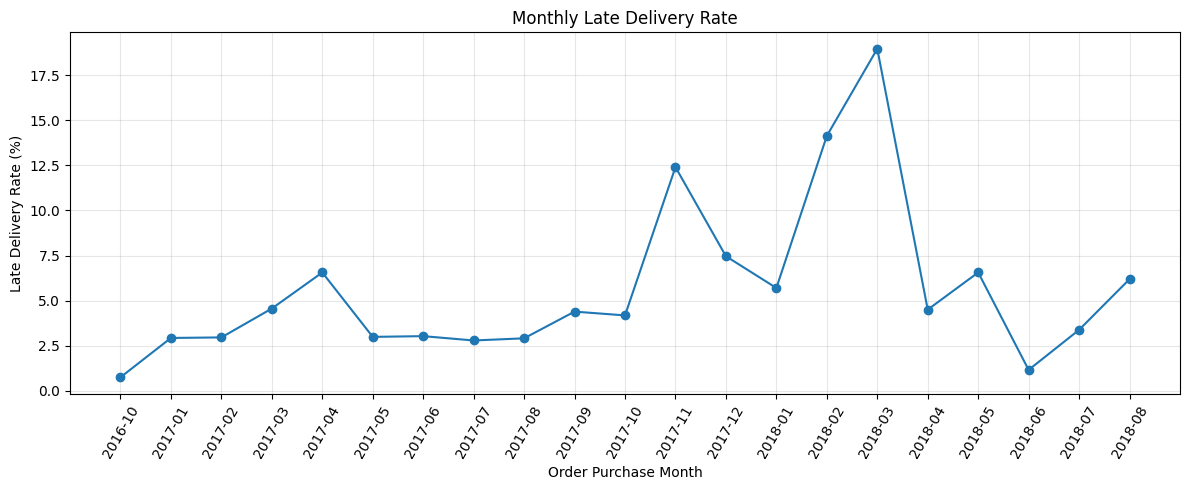

Chart saved successfully: /content/reports/figures/monthly_late_delivery_rate.png


In [ ]:

import matplotlib.pyplot as plt
import os

# Ensure the figures folder exists
os.makedirs("/content/reports/figures", exist_ok=True)

# Sort months chronologically
monthly_delay = monthly_delay.sort_values("purchase_month")

# Exclude months with fewer than 100 eligible orders
# to avoid misleading rates from tiny samples
chart_data = monthly_delay[
    monthly_delay["total_eligible_orders"] >= 100
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    chart_data["purchase_month"],
    chart_data["late_delivery_rate_pct"],
    marker="o"
)

plt.title("Monthly Late Delivery Rate")
plt.xlabel("Order Purchase Month")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save chart
chart_path = "/content/reports/figures/monthly_late_delivery_rate.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully:", chart_path)


In [ ]:

monthly_delay.to_csv(
    "/content/reports/week2_monthly_delay_analysis.csv",
    index=False
)

print("Monthly delay analysis saved successfully!")


Monthly delay analysis saved successfully!


In [ ]:

# Use the existing monthly_orders dataset from Week 2

monthly_orders["purchase_day"] = (
    monthly_orders["order_purchase_timestamp"]
    .dt.day_name()
)

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_delay = (
    monthly_orders.groupby("purchase_day")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=("is_late", "sum")
    )
    .reindex(day_order)
    .reset_index()
)

weekday_delay["late_delivery_rate_pct"] = (
    weekday_delay["late_orders"]
    / weekday_delay["total_orders"] * 100
).round(2)

display(weekday_delay)


,purchase_day,total_orders,late_orders,late_delivery_rate_pct
0,Monday,15701,1168,7.44
1,Tuesday,15502,1093,7.05
2,Wednesday,15074,990,6.57
3,Thursday,14322,903,6.30
4,Friday,13684,960,7.02
5,Saturday,10555,696,6.59
6,Sunday,11632,724,6.22


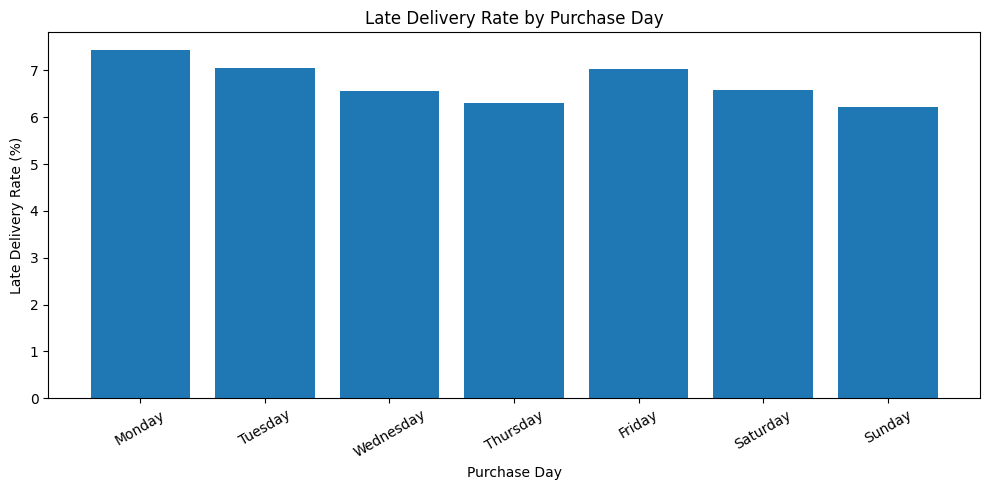

Weekday analysis CSV saved.
Weekday chart saved: /content/reports/figures/weekday_late_delivery_rate.png


In [ ]:

import os
import matplotlib.pyplot as plt

os.makedirs("/content/reports/figures", exist_ok=True)

# Save the analysis table
weekday_delay.to_csv(
    "/content/reports/week2_weekday_delay_analysis.csv",
    index=False
)

# Create a chart
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_delay["purchase_day"],
    weekday_delay["late_delivery_rate_pct"]
)

plt.title("Late Delivery Rate by Purchase Day")
plt.xlabel("Purchase Day")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()

chart_path = "/content/reports/figures/weekday_late_delivery_rate.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Weekday analysis CSV saved.")
print("Weekday chart saved:", chart_path)


In [ ]:

# Create a copy of orders with the required timestamps
processing_data = orders.dropna(
    subset=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

# Calculate purchase-to-approval time in hours
processing_data["approval_hours"] = (
    processing_data["order_approved_at"]
    - processing_data["order_purchase_timestamp"]
).dt.total_seconds() / 3600

# Identify late deliveries
processing_data["is_late"] = (
    processing_data["order_delivered_customer_date"].dt.normalize()
    > processing_data["order_estimated_delivery_date"].dt.normalize()
)

# Remove invalid negative approval durations
processing_data = processing_data[
    processing_data["approval_hours"] >= 0
]

# Summarize processing time
print("Average purchase-to-approval time (hours):",
      round(processing_data["approval_hours"].mean(), 2))

print("Median purchase-to-approval time (hours):",
      round(processing_data["approval_hours"].median(), 2))

# Compare late-delivery rate by approval-time group
processing_data["approval_group"] = pd.cut(
    processing_data["approval_hours"],
    bins=[-0.001, 1, 6, 24, float("inf")],
    labels=["Up to 1 hour", "1–6 hours", "6–24 hours", "Over 24 hours"]
)

approval_delay = processing_data.groupby(
    "approval_group", observed=False
).agg(
    total_orders=("order_id", "nunique"),
    late_orders=("is_late", "sum")
).reset_index()

approval_delay["late_delivery_rate_pct"] = (
    approval_delay["late_orders"]
    / approval_delay["total_orders"] * 100
).round(2)

display(approval_delay)


Average purchase-to-approval time (hours): 10.28
Median purchase-to-approval time (hours): 0.34


,approval_group,total_orders,late_orders,late_delivery_rate_pct
0,Up to 1 hour,61706,3884,6.29
1,1–6 hours,5869,486,8.28
2,6–24 hours,12014,795,6.62
3,Over 24 hours,16873,1370,8.12


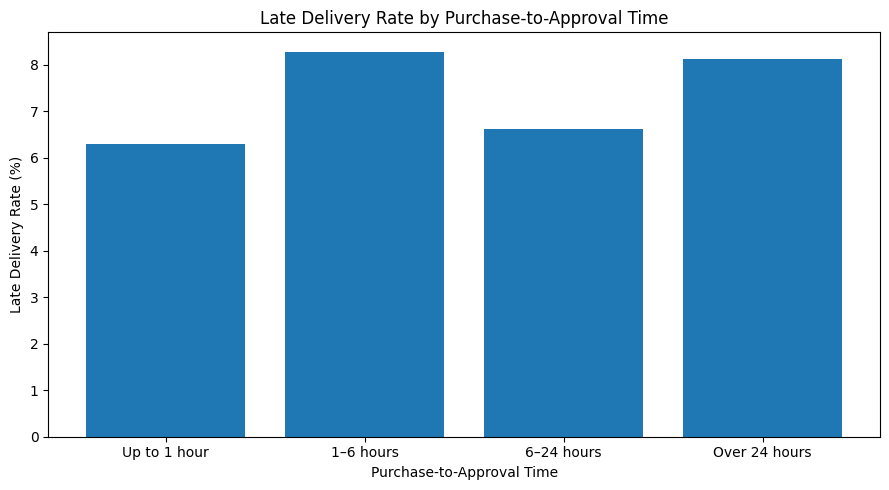

Approval-time analysis saved.
Chart saved: /content/reports/figures/approval_time_vs_late_delivery.png


In [ ]:

import os
import matplotlib.pyplot as plt

os.makedirs("/content/reports/figures", exist_ok=True)

# Save analysis table
approval_delay.to_csv(
    "/content/reports/week2_approval_delay_analysis.csv",
    index=False
)

# Create chart
plt.figure(figsize=(9, 5))

plt.bar(
    approval_delay["approval_group"].astype(str),
    approval_delay["late_delivery_rate_pct"]
)

plt.title("Late Delivery Rate by Purchase-to-Approval Time")
plt.xlabel("Purchase-to-Approval Time")
plt.ylabel("Late Delivery Rate (%)")
plt.tight_layout()

chart_path = (
    "/content/reports/figures/"
    "approval_time_vs_late_delivery.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Approval-time analysis saved.")
print("Chart saved:", chart_path)


In [ ]:

import os

required_files = [
    "/content/reports/week2_kpi_summary.csv",
    "/content/reports/week2_monthly_delay_analysis.csv",
    "/content/reports/week2_weekday_delay_analysis.csv",
    "/content/reports/week2_approval_delay_analysis.csv",
    "/content/reports/figures/monthly_late_delivery_rate.png",
    "/content/reports/figures/weekday_late_delivery_rate.png",
    "/content/reports/figures/approval_time_vs_late_delivery.png"
]

print("WEEK 2 OUTPUT CHECK")
print("-" * 40)

for path in required_files:
    status = "FOUND" if os.path.exists(path) else "MISSING"
    print(f"{status}: {path}")

print("\nCheck completed.")


WEEK 2 OUTPUT CHECK
----------------------------------------
FOUND: /content/reports/week2_kpi_summary.csv
FOUND: /content/reports/week2_monthly_delay_analysis.csv
FOUND: /content/reports/week2_weekday_delay_analysis.csv
FOUND: /content/reports/week2_approval_delay_analysis.csv
FOUND: /content/reports/figures/monthly_late_delivery_rate.png
FOUND: /content/reports/figures/weekday_late_delivery_rate.png
FOUND: /content/reports/figures/approval_time_vs_late_delivery.png

Check completed.


In [ ]:

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

# Select delivered orders with both actual and estimated dates
delay_data = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

# Compare calendar dates
delay_data["actual_date"] = (
    delay_data["order_delivered_customer_date"].dt.normalize()
)

delay_data["estimated_date"] = (
    delay_data["order_estimated_delivery_date"].dt.normalize()
)

# Positive = late; negative = early; zero = on estimated date
delay_data["delivery_variance_days"] = (
    delay_data["actual_date"] - delay_data["estimated_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Summarize delivery performance
late_only = delay_data[
    delay_data["delivery_variance_days"] > 0
]

delay_summary = pd.DataFrame({
    "Metric": [
        "Eligible delivered orders",
        "Late orders",
        "Early orders",
        "Orders delivered on estimated date",
        "Average days late among late orders",
        "Median days late among late orders",
        "Maximum days late"
    ],
    "Value": [
        len(delay_data),
        (delay_data["delivery_variance_days"] > 0).sum(),
        (delay_data["delivery_variance_days"] < 0).sum(),
        (delay_data["delivery_variance_days"] == 0).sum(),
        round(late_only["delivery_variance_days"].mean(), 2),
        round(late_only["delivery_variance_days"].median(), 2),
        round(late_only["delivery_variance_days"].max(), 2)
    ]
})

display(delay_summary)


,Metric,Value
0,Eligible delivered orders,96470.00
1,Late orders,6534.00
2,Early orders,88644.00
3,Orders delivered on estimated date,1292.00
4,Average days late among late orders,10.62
5,Median days late among late orders,7.00
6,Maximum days late,188.00


In [ ]:

os.makedirs("/content/reports", exist_ok=True)

delay_summary.to_csv(
    "/content/reports/week2_delivery_variance_summary.csv",
    index=False
)

print("Delivery variance summary saved successfully!")


Delivery variance summary saved successfully!


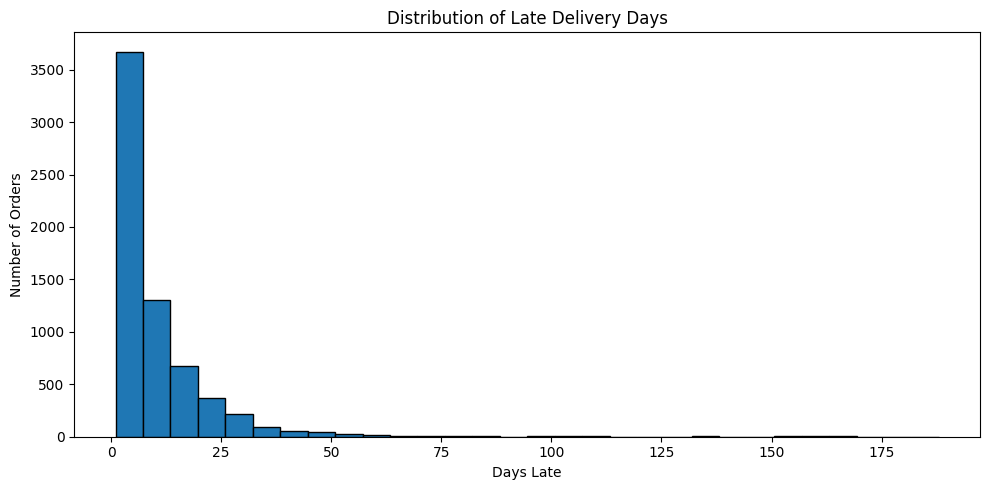

Late-delivery distribution chart saved: /content/reports/figures/late_delivery_days_distribution.png


In [ ]:

import matplotlib.pyplot as plt
import os

# Keep only orders that arrived late
late_delays = delay_data.loc[
    delay_data["delivery_variance_days"] > 0,
    "delivery_variance_days"
]

os.makedirs("/content/reports/figures", exist_ok=True)

plt.figure(figsize=(10, 5))

plt.hist(late_delays, bins=30, edgecolor="black")

plt.title("Distribution of Late Delivery Days")
plt.xlabel("Days Late")
plt.ylabel("Number of Orders")
plt.tight_layout()

chart_path = (
    "/content/reports/figures/"
    "late_delivery_days_distribution.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Late-delivery distribution chart saved:", chart_path)


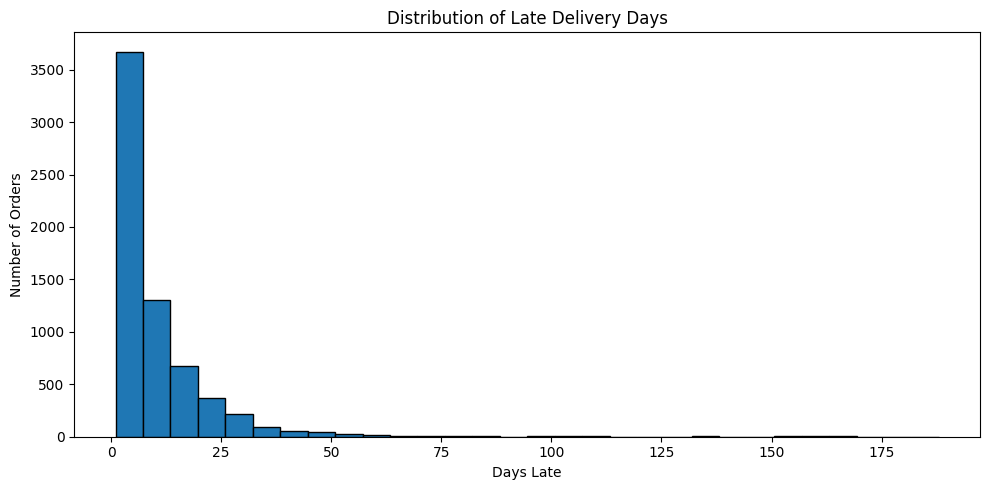

Chart saved successfully: /content/reports/figures/late_delivery_days_distribution.png


In [ ]:

import matplotlib.pyplot as plt
import os

os.makedirs("/content/reports/figures", exist_ok=True)

late_delays = delay_data.loc[
    delay_data["delivery_variance_days"] > 0,
    "delivery_variance_days"
]

plt.figure(figsize=(10, 5))
plt.hist(late_delays, bins=30, edgecolor="black")

plt.title("Distribution of Late Delivery Days")
plt.xlabel("Days Late")
plt.ylabel("Number of Orders")
plt.tight_layout()

chart_path = "/content/reports/figures/late_delivery_days_distribution.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully:", chart_path)


In [ ]:
import os

files_to_check = [
    "/content/olist_order_items_dataset.csv",
    "/content/olist_sellers_dataset.csv"
]

for path in files_to_check:
    print(
        "FOUND" if os.path.exists(path) else "MISSING",
        path
    )

FOUND /content/olist_order_items_dataset.csv
FOUND /content/olist_sellers_dataset.csv


In [ ]:

import pandas as pd
import numpy as np

# Load seller and order-item data
order_items = pd.read_csv("/content/olist_order_items_dataset.csv")
sellers = pd.read_csv("/content/olist_sellers_dataset.csv")

# Keep only delivered orders with valid delivery dates
seller_orders = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

# Identify late deliveries by calendar date
seller_orders["is_late"] = (
    seller_orders["order_delivered_customer_date"].dt.normalize()
    > seller_orders["order_estimated_delivery_date"].dt.normalize()
)

# Join order items to order delivery outcomes
seller_items = order_items.merge(
    seller_orders[["order_id", "is_late"]],
    on="order_id",
    how="inner"
)

# Calculate order-level seller performance
seller_performance = seller_items.groupby("seller_id").agg(
    total_items=("order_id", "size"),
    total_orders=("order_id", "nunique"),
    late_orders=("is_late", "sum")
).reset_index()

seller_performance["late_delivery_rate_pct"] = (
    seller_performance["late_orders"]
    / seller_performance["total_orders"] * 100
).round(2)

# Include seller location details
seller_performance = seller_performance.merge(
    sellers,
    on="seller_id",
    how="left"
)

print("Seller performance analysis created!")
print("Number of sellers analyzed:", len(seller_performance))
display(seller_performance.head())


Seller performance analysis created!
Number of sellers analyzed: 2970


,seller_id,total_items,total_orders,late_orders,late_delivery_rate_pct,seller_zip_code_prefix,seller_city,seller_state
0,0015a82c2db000af6aaaf3ae2ecb0532,3,3,0,0.00,9080,santo andre,SP
1,001cca7ae9ae17fb1caed9dfb1094831,234,195,12,6.15,29156,cariacica,ES
2,002100f778ceb8431b7a1020ff7ab48f,54,50,9,18.00,14405,franca,SP
3,003554e2dce176b5555353e4f3555ac8,1,1,0,0.00,74565,goiania,GO
4,004c9cd9d87a3c30c522c48c4fc07416,168,156,10,6.41,14940,ibitinga,SP


In [ ]:

# Filter sellers with at least 20 eligible orders
reliable_sellers = seller_performance[
    seller_performance["total_orders"] >= 20
].copy()

# Highest late-delivery rates
top_late_sellers = reliable_sellers.sort_values(
    by=["late_delivery_rate_pct", "total_orders"],
    ascending=[False, False]
).head(10)

print("Top 10 sellers by late-delivery rate")
display(
    top_late_sellers[
        [
            "seller_id",
            "seller_city",
            "total_orders",
            "late_orders",
            "late_delivery_rate_pct"
        ]
    ]
)


Top 10 sellers by late-delivery rate


,seller_id,seller_city,total_orders,late_orders,late_delivery_rate_pct
451,2709af9587499e95e803a6498a5a56e9,sao paulo,25,23,92.00
1000,54965bbe3e4f07ae045b90b0b8541f52,foz do iguacu,73,26,35.62
2766,ede0c03645598cdfc63ca8237acbe73d,ribeirao preto,43,15,34.88
1543,821fb029fc6e495ca4f08a35d51e53a5,sao paulo,24,8,33.33
2011,ad781527c93d00d89a11eecd9dcad7c1,sao jose do rio preto,38,12,31.58
480,2a261b5b644fa05f4f2700eb93544f2c,porto ferreira,51,16,31.37
478,2a1348e9addc1af5aaa619b1a3679d6b,belo horizonte,48,15,31.25
1556,835f0f7810c76831d6c7d24c7a646d4d,sao paulo,42,13,30.95
57,054694fa03fe82cec4b7551487331d74,itajobi,20,6,30.00
347,1dfe5347016252a7884b694d4f10f5c4,ibitinga,20,6,30.00


In [ ]:

import os

os.makedirs("/content/reports", exist_ok=True)

reliable_sellers.to_csv(
    "/content/reports/week2_seller_performance.csv",
    index=False
)

top_late_sellers.to_csv(
    "/content/reports/week2_top_late_sellers.csv",
    index=False
)

print("Seller performance files saved successfully!")


Seller performance files saved successfully!


In [ ]:

city_performance = seller_items.merge(
    sellers[["seller_id", "seller_city"]],
    on="seller_id",
    how="left"
)

city_performance = city_performance.dropna(
    subset=["seller_city"]
)

# One row per seller-order, to avoid counting multiple items
# from the same seller in the same order more than once.
city_performance = city_performance.drop_duplicates(
    subset=["order_id", "seller_id"]
)

city_summary = city_performance.groupby("seller_city").agg(
    eligible_orders=("order_id", "nunique"),
    late_orders=("is_late", "sum")
).reset_index()

city_summary["late_delivery_rate_pct"] = (
    city_summary["late_orders"]
    / city_summary["eligible_orders"] * 100
).round(2)

city_summary = city_summary[
    city_summary["eligible_orders"] >= 100
].sort_values(
    "late_delivery_rate_pct",
    ascending=False
)

display(city_summary.head(10))


,seller_city,eligible_orders,late_orders,late_delivery_rate_pct
500,sao luis,389,74,19.02
190,foz do iguacu,173,27,15.61
469,santana de parnaiba,137,21,15.33
402,pirituba,151,19,12.58
291,laranjal paulista,223,27,12.11
430,ribeirao preto,1965,229,11.65
413,porto ferreira,166,19,11.45
253,itatiba,446,51,11.43
191,franca,592,66,11.15
209,guara,228,25,10.96


In [ ]:

# Recalculate the main delivery KPIs independently

valid_deliveries = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

valid_deliveries["actual_date"] = (
    valid_deliveries["order_delivered_customer_date"].dt.normalize()
)

valid_deliveries["estimated_date"] = (
    valid_deliveries["order_estimated_delivery_date"].dt.normalize()
)

valid_deliveries["is_late"] = (
    valid_deliveries["actual_date"]
    > valid_deliveries["estimated_date"]
)

valid_deliveries["is_early"] = (
    valid_deliveries["actual_date"]
    < valid_deliveries["estimated_date"]
)

valid_deliveries["is_on_estimated_date"] = (
    valid_deliveries["actual_date"]
    == valid_deliveries["estimated_date"]
)

eligible_count = valid_deliveries["order_id"].nunique()
late_count = valid_deliveries["is_late"].sum()
early_count = valid_deliveries["is_early"].sum()
on_date_count = valid_deliveries["is_on_estimated_date"].sum()

print("ELIGIBLE DELIVERED ORDERS:", eligible_count)
print("LATE ORDERS:", late_count)
print("EARLY ORDERS:", early_count)
print("ON ESTIMATED DATE:", on_date_count)
print("OUTCOME COUNTS MATCH:",
      eligible_count == late_count + early_count + on_date_count)

print("RECALCULATED LATE RATE (%):",
      round(late_count / eligible_count * 100, 2))

print("RECALCULATED ON-TIME OR EARLY RATE (%):",
      round((early_count + on_date_count) / eligible_count * 100, 2))


ELIGIBLE DELIVERED ORDERS: 96470
LATE ORDERS: 6534
EARLY ORDERS: 88644
ON ESTIMATED DATE: 1292
OUTCOME COUNTS MATCH: True
RECALCULATED LATE RATE (%): 6.77
RECALCULATED ON-TIME OR EARLY RATE (%): 93.23


In [ ]:

import os

required_files = [
    "/content/reports/week2_kpi_summary.csv",
    "/content/reports/week2_monthly_delay_analysis.csv",
    "/content/reports/week2_weekday_delay_analysis.csv",
    "/content/reports/week2_approval_delay_analysis.csv",
    "/content/reports/week2_delivery_variance_summary.csv",
    "/content/reports/week2_seller_performance.csv",
    "/content/reports/week2_top_late_sellers.csv",
    "/content/reports/figures/monthly_late_delivery_rate.png",
    "/content/reports/figures/weekday_late_delivery_rate.png",
    "/content/reports/figures/approval_time_vs_late_delivery.png",
    "/content/reports/figures/late_delivery_days_distribution.png"
]

missing_files = []

for path in required_files:
    if os.path.exists(path):
        print("FOUND:", path)
    else:
        print("MISSING:", path)
        missing_files.append(path)

print("\nFiles checked:", len(required_files))
print("Files missing:", len(missing_files))

if not missing_files:
    print("All checked Week 2 outputs are present!")


FOUND: /content/reports/week2_kpi_summary.csv
FOUND: /content/reports/week2_monthly_delay_analysis.csv
FOUND: /content/reports/week2_weekday_delay_analysis.csv
FOUND: /content/reports/week2_approval_delay_analysis.csv
FOUND: /content/reports/week2_delivery_variance_summary.csv
FOUND: /content/reports/week2_seller_performance.csv
FOUND: /content/reports/week2_top_late_sellers.csv
FOUND: /content/reports/figures/monthly_late_delivery_rate.png
FOUND: /content/reports/figures/weekday_late_delivery_rate.png
FOUND: /content/reports/figures/approval_time_vs_late_delivery.png
FOUND: /content/reports/figures/late_delivery_days_distribution.png

Files checked: 11
Files missing: 0
All checked Week 2 outputs are present!


In [ ]:

import pandas as pd
import os

# Count all orders in the original orders dataset
total_orders = orders["order_id"].nunique()

# Count cancelled orders
cancelled_orders = orders.loc[
    orders["order_status"] == "canceled",
    "order_id"
].nunique()

# Calculate cancellation rate using all orders as denominator
cancellation_rate = (
    cancelled_orders / total_orders * 100
    if total_orders > 0 else 0
)

cancellation_summary = pd.DataFrame({
    "Metric": [
        "Total orders",
        "Cancelled orders",
        "Cancellation rate (%)"
    ],
    "Value": [
        total_orders,
        cancelled_orders,
        round(cancellation_rate, 2)
    ]
})

display(cancellation_summary)

# Save the result
os.makedirs("/content/reports", exist_ok=True)

cancellation_summary.to_csv(
    "/content/reports/week2_cancellation_summary.csv",
    index=False
)

print("Cancellation summary saved successfully!")


,Metric,Value
0,Total orders,99441.00
1,Cancelled orders,625.00
2,Cancellation rate (%),0.63


Cancellation summary saved successfully!


In [ ]:

reviews = pd.read_csv("/content/olist_order_reviews_dataset.csv")

print("Review dataset shape:", reviews.shape)
print("\nAvailable columns:")
print(reviews.columns.tolist())

display(reviews.head())


Review dataset shape: (99224, 7)

Available columns:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [ ]:

# Convert review scores to numeric values
reviews["review_score"] = pd.to_numeric(
    reviews["review_score"],
    errors="coerce"
)

# Keep the columns needed for this analysis
review_data = reviews[
    ["order_id", "review_score"]
].dropna(subset=["order_id", "review_score"])

# Join reviews to valid delivered orders
rating_data = valid_deliveries[
    ["order_id", "is_late"]
].merge(
    review_data,
    on="order_id",
    how="inner"
)

print("Orders matched with reviews:", len(rating_data))
print("Unique matched orders:", rating_data["order_id"].nunique())
print("Missing review scores:", rating_data["review_score"].isna().sum())

display(rating_data.head())


Orders matched with reviews: 96353
Unique matched orders: 95824
Missing review scores: 0


,order_id,is_late,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,False,4
1,53cdb2fc8bc7dce0b6741e2150273451,False,4
2,47770eb9100c2d0c44946d9cf07ec65d,False,5
3,949d5b44dbf5de918fe9c16f97b45f8a,False,5
4,ad21c59c0840e6cb83a9ceb5573f8159,False,5


In [ ]:

rating_comparison = rating_data.groupby("is_late").agg(
    reviewed_orders=("order_id", "nunique"),
    average_review_score=("review_score", "mean"),
    median_review_score=("review_score", "median")
).reset_index()

rating_comparison["delivery_group"] = rating_comparison[
    "is_late"
].map({
    True: "Late delivery",
    False: "On-time or early delivery"
})

rating_comparison = rating_comparison[
    [
        "delivery_group",
        "reviewed_orders",
        "average_review_score",
        "median_review_score"
    ]
]

rating_comparison[
    ["average_review_score", "median_review_score"]
] = rating_comparison[
    ["average_review_score", "median_review_score"]
].round(2)

display(rating_comparison)


,delivery_group,reviewed_orders,average_review_score,median_review_score
0,On-time or early delivery,89443,4.29,5.0
1,Late delivery,6381,2.27,1.0


In [ ]:

import os

os.makedirs("/content/reports", exist_ok=True)

rating_comparison.to_csv(
    "/content/reports/week2_customer_rating_comparison.csv",
    index=False
)

print("Customer rating comparison saved successfully!")


Customer rating comparison saved successfully!


In [ ]:

# Find datasets already loaded in your notebook

for name in ["orders", "reviews", "seller_performance",
             "sellers", "products", "items",
             "order_items", "olist_items"]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", obj.shape if hasattr(obj, "shape") else type(obj))


orders -> (99441, 8)
reviews -> (99224, 7)
seller_performance -> (2970, 8)
sellers -> (3095, 4)
order_items -> (112650, 7)


In [ ]:

# Check columns for the remaining Week 2 comparisons

print("ORDER ITEMS COLUMNS:")
print(order_items.columns.tolist())

print("\nSELLERS COLUMNS:")
print(sellers.columns.tolist())

print("\nORDERS COLUMNS:")
print(orders.columns.tolist())

# Load product dataset if it is not already loaded
products = pd.read_csv("/content/olist_products_dataset.csv")

print("\nPRODUCTS COLUMNS:")
print(products.columns.tolist())


ORDER ITEMS COLUMNS:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

SELLERS COLUMNS:
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

ORDERS COLUMNS:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

PRODUCTS COLUMNS:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


In [ ]:

# Week 2: Product-category delivery analysis

# Attach product categories to order items
category_items = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Attach delivery outcomes from our existing validated dataset
category_items = category_items.merge(
    valid_deliveries[["order_id", "is_late"]],
    on="order_id",
    how="inner"
)

# Count each order only once per category
category_items = category_items.drop_duplicates(
    subset=["order_id", "product_category_name"]
)

# Summarize delivery performance by category
category_summary = category_items.groupby(
    "product_category_name",
    dropna=False
).agg(
    eligible_orders=("order_id", "nunique"),
    late_orders=("is_late", "sum")
).reset_index()

category_summary["late_delivery_rate_pct"] = (
    category_summary["late_orders"]
    / category_summary["eligible_orders"] * 100
).round(2)

# Keep categories with at least 100 eligible orders
category_summary = category_summary[
    category_summary["eligible_orders"] >= 100
].sort_values(
    "late_delivery_rate_pct",
    ascending=False
)

display(category_summary.head(15))

# Save the result
category_summary.to_csv(
    "/content/reports/week2_product_category_analysis.csv",
    index=False
)

print("Product-category analysis saved successfully!")


,product_category_name,eligible_orders,late_orders,late_delivery_rate_pct
7,audio,348,41,11.78
14,casa_conforto,392,37,9.44
39,fashion_underwear_e_moda_praia,117,11,9.40
49,livros_tecnicos,256,21,8.20
9,bebes,2809,226,8.05
55,moveis_escritorio,1254,101,8.05
6,artigos_de_natal,125,10,8.00
30,eletronicos,2517,192,7.63
45,instrumentos_musicais,611,46,7.53
11,beleza_saude,8647,649,7.51


Product-category analysis saved successfully!


In [ ]:

print("Order columns:")
print(orders.columns.tolist())

print("\nOrder-item columns:")
print(order_items.columns.tolist())


Order columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Order-item columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


In [ ]:

import pandas as pd
import os

os.makedirs("/content/reports", exist_ok=True)

kpi_definitions = pd.DataFrame([
    {
        "KPI": "Total Orders",
        "Definition": "Count of unique order IDs in the dataset",
        "Denominator": "Not applicable"
    },
    {
        "KPI": "Cancellation Rate (%)",
        "Definition": "Cancelled unique orders divided by all unique orders, multiplied by 100",
        "Denominator": "All unique orders"
    },
    {
        "KPI": "Late Delivery Rate (%)",
        "Definition": "Eligible delivered orders arriving after the estimated delivery date, divided by eligible delivered orders, multiplied by 100",
        "Denominator": "Delivered orders with actual and estimated delivery dates"
    },
    {
        "KPI": "On-Time or Early Rate (%)",
        "Definition": "Eligible delivered orders arriving on or before the estimated date, divided by eligible delivered orders, multiplied by 100",
        "Denominator": "Delivered orders with actual and estimated delivery dates"
    },
    {
        "KPI": "Average Delivery Duration (Days)",
        "Definition": "Average time from purchase timestamp to actual customer delivery timestamp",
        "Denominator": "Delivered orders with valid purchase and delivery timestamps"
    },
    {
        "KPI": "Average Late Days",
        "Definition": "Average number of calendar days after the estimated delivery date among late orders",
        "Denominator": "Late orders with valid delivery dates"
    }
])

kpi_definitions.to_csv(
    "/content/reports/week2_kpi_definitions.csv",
    index=False
)

display(kpi_definitions)
print("KPI definitions saved successfully!")


,KPI,Definition,Denominator
0,Total Orders,Count of unique order IDs in the dataset,Not applicable
1,Cancellation Rate (%),Cancelled unique orders divided by all unique ...,All unique orders
2,Late Delivery Rate (%),Eligible delivered orders arriving after the e...,Delivered orders with actual and estimated del...
3,On-Time or Early Rate (%),Eligible delivered orders arriving on or befor...,Delivered orders with actual and estimated del...
4,Average Delivery Duration (Days),Average time from purchase timestamp to actual...,Delivered orders with valid purchase and deliv...
5,Average Late Days,Average number of calendar days after the esti...,Late orders with valid delivery dates


KPI definitions saved successfully!


In [ ]:

import os
import pandas as pd

os.makedirs("/content/data/processed", exist_ok=True)

# Check the existing KPI summary
kpi_path = "/content/reports/week2_kpi_summary.csv"

if os.path.exists(kpi_path):
    print("KPI summary found:")
    display(pd.read_csv(kpi_path))
else:
    print("KPI summary file not found.")

# Save the validated delivery dataset used for delivery KPIs
validated_path = "/content/data/processed/week2_validated_deliveries.csv"

validated_deliveries = valid_deliveries.copy()
validated_deliveries.to_csv(validated_path, index=False)

print("\nValidated delivery dataset saved:", validated_path)
print("Rows:", len(validated_deliveries))
print("Columns:", len(validated_deliveries.columns))
print("Missing actual delivery dates:",
      validated_deliveries["order_delivered_customer_date"].isna().sum())
print("Missing estimated delivery dates:",
      validated_deliveries["order_estimated_delivery_date"].isna().sum())


KPI summary found:


,KPI,Value
0,Total Orders,99441.00
1,Delivered Orders,96478.00
2,Orders Eligible for Delivery-Time KPI,96470.00
3,Average Delivery Time (Days),12.56
4,Orders Eligible for Delivery Outcome KPI,96470.00
5,On-Time or Early Delivery Rate (%),93.23
6,Late Delivery Rate (%),6.77



Validated delivery dataset saved: /content/data/processed/week2_validated_deliveries.csv
Rows: 96470
Columns: 13
Missing actual delivery dates: 0
Missing estimated delivery dates: 0


In [ ]:

import pandas as pd
import os

os.makedirs("/content/reports", exist_ok=True)

interim_findings = pd.DataFrame([
    {
        "Area": "Overall delivery performance",
        "Finding": "93.23% of eligible delivered orders arrived on or before the estimated date; 6.77% arrived late."
    },
    {
        "Area": "Delivery duration",
        "Finding": "Average delivery duration was 12.56 days for eligible delivered orders."
    },
    {
        "Area": "Cancellation",
        "Finding": "625 of 99,441 unique orders were canceled, giving a cancellation rate of 0.63%."
    },
    {
        "Area": "Monthly patterns",
        "Finding": "Late-delivery rates varied by purchase month; some months had noticeably higher rates."
    },
    {
        "Area": "Weekday patterns",
        "Finding": "Late-delivery rates differed across purchase weekdays, ranging from approximately 6.30% to 7.44% in the analysis."
    },
    {
        "Area": "Customer ratings",
        "Finding": "Average review score was 4.29 for on-time or early deliveries and 2.27 for late deliveries; this is an association, not proof of causation."
    },
    {
        "Area": "Product categories",
        "Finding": "Audio had the highest late-delivery rate among the displayed categories with at least 100 eligible orders, at 11.78%."
    },
    {
        "Area": "Seller cities",
        "Finding": "São Luís had a 19.02% late-delivery rate among the displayed cities with at least 100 eligible orders."
    },
    {
        "Area": "Carrier comparison limitation",
        "Finding": "The available order data has a carrier handover timestamp but no carrier name or carrier ID, so individual carrier performance cannot be compared."
    }
])

interim_findings.to_csv(
    "/content/reports/week2_interim_findings.csv",
    index=False
)

display(interim_findings)
print("Week 2 interim findings saved successfully!")


,Area,Finding
0,Overall delivery performance,93.23% of eligible delivered orders arrived on...
1,Delivery duration,Average delivery duration was 12.56 days for e...
2,Cancellation,"625 of 99,441 unique orders were canceled, giv..."
3,Monthly patterns,Late-delivery rates varied by purchase month; ...
4,Weekday patterns,Late-delivery rates differed across purchase w...
5,Customer ratings,Average review score was 4.29 for on-time or e...
6,Product categories,Audio had the highest late-delivery rate among...
7,Seller cities,São Luís had a 19.02% late-delivery rate among...
8,Carrier comparison limitation,The available order data has a carrier handove...


Week 2 interim findings saved successfully!


In [ ]:

import os

required_files = [
    "/content/reports/week2_kpi_summary.csv",
    "/content/reports/week2_cancellation_summary.csv",
    "/content/reports/week2_kpi_definitions.csv",
    "/content/reports/week2_interim_findings.csv",
    "/content/reports/week2_customer_rating_comparison.csv",
    "/content/reports/week2_product_category_analysis.csv",
    "/content/data/processed/week2_validated_deliveries.csv"
]

for path in required_files:
    print(
        "FOUND: " if os.path.exists(path) else "MISSING: ",
        path
    )

print("\nCheck completed.")


FOUND:  /content/reports/week2_kpi_summary.csv
FOUND:  /content/reports/week2_cancellation_summary.csv
FOUND:  /content/reports/week2_kpi_definitions.csv
FOUND:  /content/reports/week2_interim_findings.csv
FOUND:  /content/reports/week2_customer_rating_comparison.csv
FOUND:  /content/reports/week2_product_category_analysis.csv
FOUND:  /content/data/processed/week2_validated_deliveries.csv

Check completed.


In [2]:

import pandas as pd
import os

# Reuse the validated Week 2 dataset
week3_data = valid_deliveries.copy()

date_columns = [
    "order_purchase_timestamp",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    week3_data[col] = pd.to_datetime(
        week3_data[col], errors="coerce"
    )

# Purchase to carrier handover
week3_data["processing_proxy_days"] = (
    week3_data["order_delivered_carrier_date"]
    - week3_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Carrier handover to customer delivery
week3_data["transit_days"] = (
    week3_data["order_delivered_customer_date"]
    - week3_data["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

# Purchase to customer delivery
week3_data["total_delivery_days"] = (
    week3_data["order_delivered_customer_date"]
    - week3_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Summarize each interval, excluding negative or missing durations
metrics = {
    "Purchase to carrier handover": "processing_proxy_days",
    "Carrier handover to customer": "transit_days",
    "Purchase to customer delivery": "total_delivery_days"
}

rows = []

for metric, column in metrics.items():
    values = week3_data.loc[
        week3_data[column].notna() & week3_data[column].ge(0),
        column
    ]

    rows.append({
        "Metric": metric,
        "Valid orders": len(values),
        "Average days": round(values.mean(), 2),
        "Median days": round(values.median(), 2)
    })

time_summary = pd.DataFrame(rows)
display(time_summary)

os.makedirs("/content/reports", exist_ok=True)

time_summary.to_csv(
    "/content/reports/week3_processing_vs_transit.csv",
    index=False
)

print("Task 1 results saved successfully!")


NameError: name 'valid_deliveries' is not defined

In [3]:
import pandas as pd
import os

file_path = "/content/data/processed/week2_validated_deliveries.csv"

if os.path.exists(file_path):
    valid_deliveries = pd.read_csv(file_path)
    print("Week 2 dataset loaded successfully!")
    print("Dataset shape:", valid_deliveries.shape)
    display(valid_deliveries.head())
else:
    print("Dataset file not found:", file_path)

Dataset file not found: /content/data/processed/week2_validated_deliveries.csv


In [4]:
import os

print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'olist_products_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'week1_project_files.zip', 'olist_sellers_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_customers_dataset.csv', 'olist_order_reviews_dataset.csv', 'product_category_name_translation.csv', 'sample_data']


In [5]:
import pandas as pd
import os

# Load the original orders dataset
orders = pd.read_csv("/content/olist_orders_dataset.csv")

# Convert delivery date columns
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Keep delivered orders with actual and estimated delivery dates
valid_deliveries = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna()) &
    (orders["order_estimated_delivery_date"].notna())
].copy()

print("Dataset recovered successfully!")
print("Valid deliveries:", len(valid_deliveries))
print("Dataset shape:", valid_deliveries.shape)

display(valid_deliveries.head())

Dataset recovered successfully!
Valid deliveries: 96470
Dataset shape: (96470, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [6]:
import pandas as pd
import os

week3_data = valid_deliveries.copy()

# Calculate processing proxy time: purchase to carrier handover
week3_data["processing_proxy_days"] = (
    week3_data["order_delivered_carrier_date"]
    - week3_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate transit time: carrier handover to customer delivery
week3_data["transit_days"] = (
    week3_data["order_delivered_customer_date"]
    - week3_data["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

# Calculate total delivery time: purchase to customer delivery
week3_data["total_delivery_days"] = (
    week3_data["order_delivered_customer_date"]
    - week3_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Summarize the time intervals
metrics = {
    "Purchase to carrier handover": "processing_proxy_days",
    "Carrier handover to customer": "transit_days",
    "Purchase to customer delivery": "total_delivery_days"
}

rows = []

for metric, column in metrics.items():
    values = week3_data.loc[
        week3_data[column].notna() & (week3_data[column] >= 0),
        column
    ]

    rows.append({
        "Metric": metric,
        "Valid orders": len(values),
        "Average days": round(values.mean(), 2),
        "Median days": round(values.median(), 2)
    })

time_summary = pd.DataFrame(rows)
display(time_summary)

# Save the results
os.makedirs("/content/reports", exist_ok=True)

time_summary.to_csv(
    "/content/reports/week3_processing_vs_transit.csv",
    index=False
)

print("Task 1 results saved successfully!")

,Metric,Valid orders,Average days,Median days
0,Purchase to carrier handover,96304,3.23,2.21
1,Carrier handover to customer,96446,9.33,7.10
2,Purchase to customer delivery,96470,12.56,10.22


Task 1 results saved successfully!


In [8]:
import pandas as pd
import os

# Load original datasets
products = pd.read_csv("/content/olist_products_dataset.csv")
order_items = pd.read_csv("/content/olist_order_items_dataset.csv")

# Select required columns
products = products[["product_id", "product_category_name"]]
order_items = order_items[["order_id", "product_id"]]

# Join delivered orders with their product categories
items = order_items.merge(products, on="product_id", how="left")

category_orders = valid_deliveries[
    ["order_id", "order_delivered_customer_date",
     "order_estimated_delivery_date"]
].merge(items, on="order_id", how="inner")

# Calculate late delivery using calendar dates
category_orders["is_late"] = (
    category_orders["order_delivered_customer_date"].dt.normalize()
    > category_orders["order_estimated_delivery_date"].dt.normalize()
)

# Aggregate at order-category level to avoid counting an order
# multiple times within the same category
category_orders = category_orders.drop_duplicates(
    subset=["order_id", "product_category_name"]
)

category_analysis = (
    category_orders.groupby("product_category_name", dropna=False)
    .agg(
        eligible_orders=("order_id", "nunique"),
        late_orders=("is_late", "sum")
    )
    .reset_index()
)

# Keep categories with at least 100 eligible orders
category_analysis = category_analysis[
    category_analysis["eligible_orders"] >= 100
].copy()

category_analysis["late_rate_pct"] = (
    category_analysis["late_orders"]
    / category_analysis["eligible_orders"] * 100
).round(2)

category_analysis = category_analysis.sort_values(
    "late_rate_pct", ascending=False
)

display(category_analysis.head(10))

# Save recreated output
os.makedirs("/content/reports", exist_ok=True)

category_analysis.to_csv(
    "/content/reports/week3_product_category_delay_analysis.csv",
    index=False
)

print("Category delay analysis saved successfully!")

,product_category_name,eligible_orders,late_orders,late_rate_pct
7,audio,348,41,11.78
14,casa_conforto,392,37,9.44
39,fashion_underwear_e_moda_praia,117,11,9.40
49,livros_tecnicos,256,21,8.20
9,bebes,2809,226,8.05
55,moveis_escritorio,1254,101,8.05
6,artigos_de_natal,125,10,8.00
30,eletronicos,2517,192,7.63
45,instrumentos_musicais,611,46,7.53
11,beleza_saude,8647,649,7.51


Category delay analysis saved successfully!


In [9]:
import pandas as pd
import os

# Use the recovered validated dataset
monthly_data = valid_deliveries.copy()

# Ensure date columns are datetime
monthly_data["order_purchase_timestamp"] = pd.to_datetime(
    monthly_data["order_purchase_timestamp"], errors="coerce"
)
monthly_data["order_delivered_customer_date"] = pd.to_datetime(
    monthly_data["order_delivered_customer_date"], errors="coerce"
)
monthly_data["order_estimated_delivery_date"] = pd.to_datetime(
    monthly_data["order_estimated_delivery_date"], errors="coerce"
)

# Group by purchase month
monthly_data["purchase_month"] = (
    monthly_data["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

monthly_data["is_late"] = (
    monthly_data["order_delivered_customer_date"].dt.normalize()
    > monthly_data["order_estimated_delivery_date"].dt.normalize()
)

monthly_analysis = (
    monthly_data.groupby("purchase_month")
    .agg(
        eligible_orders=("order_id", "nunique"),
        late_orders=("is_late", "sum")
    )
    .reset_index()
)

monthly_analysis["late_rate_pct"] = (
    monthly_analysis["late_orders"]
    / monthly_analysis["eligible_orders"] * 100
).round(2)

display(monthly_analysis)

os.makedirs("/content/reports", exist_ok=True)

monthly_analysis.to_csv(
    "/content/reports/week3_monthly_delay_analysis.csv",
    index=False
)

print("Monthly delay analysis saved successfully!")

,purchase_month,eligible_orders,late_orders,late_rate_pct
0,2016-09,1,1,100.00
1,2016-10,265,2,0.75
2,2016-12,1,0,0.00
3,2017-01,750,22,2.93
4,2017-02,1653,49,2.96
5,2017-03,2546,116,4.56
6,2017-04,2303,151,6.56
7,2017-05,3545,106,2.99
8,2017-06,3135,95,3.03
9,2017-07,3872,108,2.79


Monthly delay analysis saved successfully!


In [10]:
# Check monthly sample sizes and rank delay rates

reliable_months = monthly_analysis[
    monthly_analysis["eligible_orders"] >= 100
].copy()

print("Highest late-delivery rates (months with at least 100 orders):")
display(
    reliable_months.sort_values(
        "late_rate_pct", ascending=False
    ).head(10)
)

print("Lowest late-delivery rates (months with at least 100 orders):")
display(
    reliable_months.sort_values(
        "late_rate_pct", ascending=True
    ).head(10)
)

Highest late-delivery rates (months with at least 100 orders):


,purchase_month,eligible_orders,late_orders,late_rate_pct
17,2018-03,7003,1328,18.96
16,2018-02,6555,926,14.13
13,2017-11,7288,904,12.40
14,2017-12,5513,411,7.46
6,2017-04,2303,151,6.56
19,2018-05,6749,443,6.56
22,2018-08,6351,393,6.19
15,2018-01,7069,403,5.70
5,2017-03,2546,116,4.56
18,2018-04,6798,306,4.50


Lowest late-delivery rates (months with at least 100 orders):


,purchase_month,eligible_orders,late_orders,late_rate_pct
1,2016-10,265,2,0.75
20,2018-06,6096,71,1.16
9,2017-07,3872,108,2.79
10,2017-08,4193,122,2.91
3,2017-01,750,22,2.93
4,2017-02,1653,49,2.96
7,2017-05,3545,106,2.99
8,2017-06,3135,95,3.03
21,2018-07,6156,208,3.38
12,2017-10,4478,187,4.18


In [11]:
import pandas as pd
import os

# Load original order items and seller datasets
order_items = pd.read_csv("/content/olist_order_items_dataset.csv")
sellers = pd.read_csv("/content/olist_sellers_dataset.csv")

# Join eligible deliveries with seller IDs
seller_orders = valid_deliveries[
    ["order_id", "order_delivered_customer_date",
     "order_estimated_delivery_date"]
].merge(
    order_items[["order_id", "seller_id"]].drop_duplicates(),
    on="order_id",
    how="inner"
)

# Calculate late deliveries
seller_orders["is_late"] = (
    pd.to_datetime(seller_orders["order_delivered_customer_date"]).dt.normalize()
    > pd.to_datetime(seller_orders["order_estimated_delivery_date"]).dt.normalize()
)

# One row per order-seller combination
seller_orders = seller_orders.drop_duplicates(["order_id", "seller_id"])

# Summarize seller performance
seller_analysis = (
    seller_orders.groupby("seller_id")
    .agg(
        eligible_orders=("order_id", "nunique"),
        late_orders=("is_late", "sum")
    )
    .reset_index()
)

seller_analysis["late_rate_pct"] = (
    seller_analysis["late_orders"]
    / seller_analysis["eligible_orders"] * 100
).round(2)

# Include only sellers with at least 50 eligible orders
seller_analysis = seller_analysis[
    seller_analysis["eligible_orders"] >= 50
].merge(sellers, on="seller_id", how="left")

seller_analysis = seller_analysis.sort_values(
    "late_rate_pct", ascending=False
)

display(
    seller_analysis[
        ["seller_id", "seller_city", "seller_state",
         "eligible_orders", "late_orders", "late_rate_pct"]
    ].head(10)
)

os.makedirs("/content/reports", exist_ok=True)

seller_analysis.to_csv(
    "/content/reports/week3_seller_delay_analysis.csv",
    index=False
)

print("Seller delay analysis saved successfully!")

,seller_id,seller_city,seller_state,eligible_orders,late_orders,late_rate_pct
143,54965bbe3e4f07ae045b90b0b8541f52,foz do iguacu,PR,73,22,30.14
316,beadbee30901a7f61d031b6b686095ad,guarulhos,SP,64,15,23.44
285,a49928bcdf77c55c6d6e05e09a9b4ca5,sao paulo,SP,96,21,21.88
191,712e6ed8aa4aa1fa65dab41fed5737e4,videira,SC,77,16,20.78
20,06a2c3af7b3aee5d69171b0e14f0ee87,sao luis,MA,389,74,19.02
1,002100f778ceb8431b7a1020ff7ab48f,franca,SP,50,9,18.00
389,ea566164622c6b439516ab18062c42cd,sao paulo,SP,50,9,18.00
331,cac4c8e7b1ca6252d8f20b2fc1a2e4af,indaiatuba,SP,74,13,17.57
159,6039e27294dc75811c0d8a39069f52c0,osasco,SP,63,11,17.46
238,88460e8ebdecbfecb5f9601833981930,maringa,PR,246,42,17.07


Seller delay analysis saved successfully!


In [12]:
import pandas as pd
import os

os.makedirs("/content/reports", exist_ok=True)

findings = [
    {
        "Priority": 1,
        "Issue": "Long transit time",
        "Evidence": "Average carrier handover-to-customer time is 9.33 days, versus 3.23 days from purchase to carrier handover.",
        "Operational hypothesis": "Transit routes, handover scheduling, or delivery capacity may contribute to long delivery times.",
        "Recommended action": "Investigate transit duration by destination and shipment route; review delays between carrier handover and delivery."
    },
    {
        "Priority": 2,
        "Issue": "High monthly late-delivery rates",
        "Evidence": "March 2018 had an 18.96% late-delivery rate across 7,003 eligible orders; February 2018 had 14.13%.",
        "Operational hypothesis": "Demand fluctuations or operational constraints may have contributed to these monthly patterns.",
        "Recommended action": "Compare order volumes, seller processing times, and transit durations during high-delay months."
    },
    {
        "Priority": 3,
        "Issue": "Product-category differences",
        "Evidence": "Audio had an 11.78% late-delivery rate across 348 eligible orders.",
        "Operational hypothesis": "Some product categories may have different handling or fulfilment requirements.",
        "Recommended action": "Review category-level fulfilment and shipping processes before introducing category-specific changes."
    },
    {
        "Priority": 4,
        "Issue": "Seller-level variation",
        "Evidence": "The highest observed seller late-delivery rate was 30.14% across 73 eligible orders.",
        "Operational hypothesis": "Seller dispatch practices or destination mix may contribute to differences.",
        "Recommended action": "Review high-delay sellers' order timelines and compare similar order volumes and destinations."
    },
    {
        "Priority": 5,
        "Issue": "Customer rating association",
        "Evidence": "Mean review score was 2.27 for late deliveries and 4.29 for on-time or early deliveries.",
        "Operational hypothesis": "Delivery experience may be associated with customer satisfaction.",
        "Recommended action": "Monitor delivery performance alongside customer ratings; do not interpret this association as proof of causation."
    }
]

findings_df = pd.DataFrame(findings)

display(findings_df)

findings_df.to_csv(
    "/content/reports/week3_prioritized_issues_recommendations.csv",
    index=False
)

print("Week 3 prioritized issues and recommendations saved successfully!")

,Priority,Issue,Evidence,Operational hypothesis,Recommended action
0,1,Long transit time,Average carrier handover-to-customer time is 9...,"Transit routes, handover scheduling, or delive...",Investigate transit duration by destination an...
1,2,High monthly late-delivery rates,March 2018 had an 18.96% late-delivery rate ac...,Demand fluctuations or operational constraints...,"Compare order volumes, seller processing times..."
2,3,Product-category differences,Audio had an 11.78% late-delivery rate across ...,Some product categories may have different han...,Review category-level fulfilment and shipping ...
3,4,Seller-level variation,The highest observed seller late-delivery rate...,Seller dispatch practices or destination mix m...,Review high-delay sellers' order timelines and...
4,5,Customer rating association,Mean review score was 2.27 for late deliveries...,Delivery experience may be associated with cus...,Monitor delivery performance alongside custome...


Week 3 prioritized issues and recommendations saved successfully!


In [13]:
import pandas as pd
import os

# 1. Overall delivery validation
check_data = valid_deliveries.copy()

check_data["is_late"] = (
    pd.to_datetime(check_data["order_delivered_customer_date"]).dt.normalize()
    > pd.to_datetime(check_data["order_estimated_delivery_date"]).dt.normalize()
)

overall_orders = check_data["order_id"].nunique()
overall_late = int(check_data["is_late"].sum())
overall_late_rate = round(overall_late / overall_orders * 100, 2)

# 2. Monthly count validation
monthly_total = int(monthly_analysis["eligible_orders"].sum())

# 3. Seller sample-size validation
seller_min_orders = int(seller_analysis["eligible_orders"].min())
seller_count = int(len(seller_analysis))

validation = pd.DataFrame([
    {
        "Check": "Overall eligible orders",
        "Result": overall_orders,
        "Expected": 96470,
        "Status": "PASS" if overall_orders == 96470 else "REVIEW"
    },
    {
        "Check": "Overall late orders",
        "Result": overall_late,
        "Expected": 6534,
        "Status": "PASS" if overall_late == 6534 else "REVIEW"
    },
    {
        "Check": "Monthly order total",
        "Result": monthly_total,
        "Expected": overall_orders,
        "Status": "PASS" if monthly_total == overall_orders else "REVIEW"
    },
    {
        "Check": "Minimum orders per included seller",
        "Result": seller_min_orders,
        "Expected": "At least 50",
        "Status": "PASS" if seller_min_orders >= 50 else "REVIEW"
    }
])

display(validation)
print("Overall late-delivery rate:", overall_late_rate, "%")
print("Sellers included:", seller_count)

os.makedirs("/content/reports", exist_ok=True)

validation.to_csv(
    "/content/reports/week3_robustness_checks.csv",
    index=False
)

print("Robustness checks saved successfully!")

,Check,Result,Expected,Status
0,Overall eligible orders,96470,96470,PASS
1,Overall late orders,6534,6534,PASS
2,Monthly order total,96470,96470,PASS
3,Minimum orders per included seller,50,At least 50,PASS


Overall late-delivery rate: 6.77 %
Sellers included: 425
Robustness checks saved successfully!


In [14]:
import os
import pandas as pd

required_files = [
    "/content/reports/week3_processing_vs_transit.csv",
    "/content/reports/week3_product_category_delay_analysis.csv",
    "/content/reports/week3_monthly_delay_analysis.csv",
    "/content/reports/week3_seller_delay_analysis.csv",
    "/content/reports/week3_prioritized_issues_recommendations.csv",
    "/content/reports/week3_robustness_checks.csv"
]

file_check = pd.DataFrame({
    "File": [os.path.basename(f) for f in required_files],
    "Exists": [os.path.exists(f) for f in required_files]
})

display(file_check)

print(
    "All required files exist:",
    file_check["Exists"].all()
)

,File,Exists
0,week3_processing_vs_transit.csv,True
1,week3_product_category_delay_analysis.csv,True
2,week3_monthly_delay_analysis.csv,True
3,week3_seller_delay_analysis.csv,True
4,week3_prioritized_issues_recommendations.csv,True
5,week3_robustness_checks.csv,True


All required files exist: True


In [15]:
import os

files_to_check = [
    "/content/data/processed/week2_validated_deliveries.csv",
    "/content/reports/week2_kpi_summary.csv",
    "/content/reports/week3_monthly_delay_analysis.csv",
    "/content/reports/week3_product_category_delay_analysis.csv",
    "/content/reports/week3_seller_delay_analysis.csv"
]

for file_path in files_to_check:
    print(
        os.path.basename(file_path),
        "->",
        "Available" if os.path.exists(file_path) else "Missing"
    )

week2_validated_deliveries.csv -> Missing
week2_kpi_summary.csv -> Missing
week3_monthly_delay_analysis.csv -> Available
week3_product_category_delay_analysis.csv -> Available
week3_seller_delay_analysis.csv -> Available


In [16]:
import pandas as pd
import os

# Load the original orders dataset
orders = pd.read_csv("/content/olist_orders_dataset.csv")

# Convert date columns
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Select delivered orders with actual and estimated delivery dates
dashboard_data = orders[
    (orders["order_status"] == "delivered") &
    orders["order_delivered_customer_date"].notna() &
    orders["order_estimated_delivery_date"].notna()
].copy()

# Calculate delivery KPIs
dashboard_data["is_late"] = (
    dashboard_data["order_delivered_customer_date"].dt.normalize()
    > dashboard_data["order_estimated_delivery_date"].dt.normalize()
)

dashboard_data["delivery_days"] = (
    dashboard_data["order_delivered_customer_date"]
    - dashboard_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

dashboard_data["purchase_month"] = (
    dashboard_data["order_purchase_timestamp"]
    .dt.to_period("M").astype(str)
)

# Save the dashboard dataset
os.makedirs("/content/data/processed", exist_ok=True)

dashboard_data.to_csv(
    "/content/data/processed/week4_dashboard_deliveries.csv",
    index=False
)

print("Dashboard dataset created successfully!")
print("Rows:", len(dashboard_data))
print("Columns:", len(dashboard_data.columns))
print("Late deliveries:", int(dashboard_data["is_late"].sum()))
print("Late delivery rate (%):",
      round(dashboard_data["is_late"].mean() * 100, 2))

display(dashboard_data.head())

Dashboard dataset created successfully!
Rows: 96470
Columns: 11
Late deliveries: 6534
Late delivery rate (%): 6.77


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,is_late,delivery_days,purchase_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,8.436574,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,13.782037,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,9.394213,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,13.208750,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,2.873877,2018-02


In [17]:
import pandas as pd
import os

data = dashboard_data.copy()

# Calculate dashboard KPIs
total_orders = data["order_id"].nunique()
late_orders = int(data["is_late"].sum())
on_time_orders = total_orders - late_orders

kpi_summary = pd.DataFrame([
    {
        "KPI": "Eligible Delivered Orders",
        "Value": total_orders,
        "Unit": "Orders"
    },
    {
        "KPI": "Late Deliveries",
        "Value": late_orders,
        "Unit": "Orders"
    },
    {
        "KPI": "On-Time or Early Deliveries",
        "Value": on_time_orders,
        "Unit": "Orders"
    },
    {
        "KPI": "Late Delivery Rate",
        "Value": round(late_orders / total_orders * 100, 2),
        "Unit": "Percent"
    },
    {
        "KPI": "On-Time or Early Rate",
        "Value": round(on_time_orders / total_orders * 100, 2),
        "Unit": "Percent"
    },
    {
        "KPI": "Average Delivery Duration",
        "Value": round(data["delivery_days"].mean(), 2),
        "Unit": "Days"
    },
    {
        "KPI": "Median Delivery Duration",
        "Value": round(data["delivery_days"].median(), 2),
        "Unit": "Days"
    }
])

display(kpi_summary)

os.makedirs("/content/reports", exist_ok=True)

kpi_summary.to_csv(
    "/content/reports/week4_dashboard_kpis.csv",
    index=False
)

print("KPI summary saved successfully!")

,KPI,Value,Unit
0,Eligible Delivered Orders,96470.00,Orders
1,Late Deliveries,6534.00,Orders
2,On-Time or Early Deliveries,89936.00,Orders
3,Late Delivery Rate,6.77,Percent
4,On-Time or Early Rate,93.23,Percent
5,Average Delivery Duration,12.56,Days
6,Median Delivery Duration,10.22,Days


KPI summary saved successfully!


In [18]:
import os
import zipfile

files_to_export = [
    "/content/data/processed/week4_dashboard_deliveries.csv",
    "/content/reports/week4_dashboard_kpis.csv",
    "/content/reports/week3_monthly_delay_analysis.csv",
    "/content/reports/week3_product_category_delay_analysis.csv",
    "/content/reports/week3_seller_delay_analysis.csv",
    "/content/reports/week3_processing_vs_transit.csv",
    "/content/reports/week3_prioritized_issues_recommendations.csv",
    "/content/reports/week3_robustness_checks.csv"
]

zip_path = "/content/week4_powerbi_files.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in files_to_export:
        if os.path.exists(file_path):
            zipf.write(file_path, arcname=os.path.basename(file_path))
            print("Added:", os.path.basename(file_path))
        else:
            print("Missing:", file_path)

print("\nZIP created:", zip_path)
print("File size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

Added: week4_dashboard_deliveries.csv
Added: week4_dashboard_kpis.csv
Added: week3_monthly_delay_analysis.csv
Added: week3_product_category_delay_analysis.csv
Added: week3_seller_delay_analysis.csv
Added: week3_processing_vs_transit.csv
Added: week3_prioritized_issues_recommendations.csv
Added: week3_robustness_checks.csv

ZIP created: /content/week4_powerbi_files.zip
File size: 7.29 MB


In [19]:
from google.colab import files
files.download("/content/week4_powerbi_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>